<a href="https://colab.research.google.com/github/NagasaiSree/ML_LabActivity/blob/main/SVM_QD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- SVC kernel = linear ---
Confusion Matrix:
 [[53 15]
 [23 29]]
Accuracy: 0.6833333333333333
              precision    recall  f1-score   support

           0       0.70      0.78      0.74        68
           1       0.66      0.56      0.60        52

    accuracy                           0.68       120
   macro avg       0.68      0.67      0.67       120
weighted avg       0.68      0.68      0.68       120



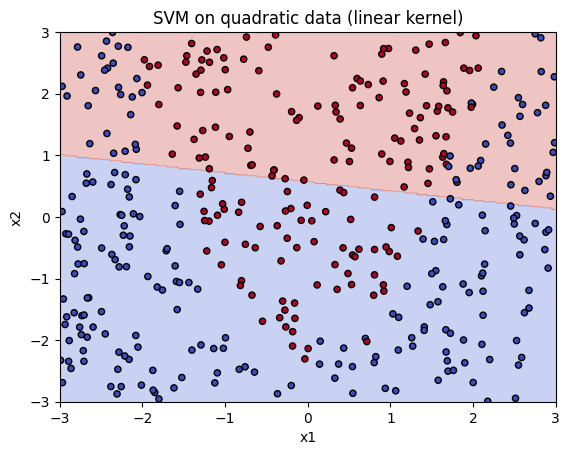

--- SVC kernel = rbf ---
Confusion Matrix:
 [[67  1]
 [ 3 49]]
Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        68
           1       0.98      0.94      0.96        52

    accuracy                           0.97       120
   macro avg       0.97      0.96      0.97       120
weighted avg       0.97      0.97      0.97       120



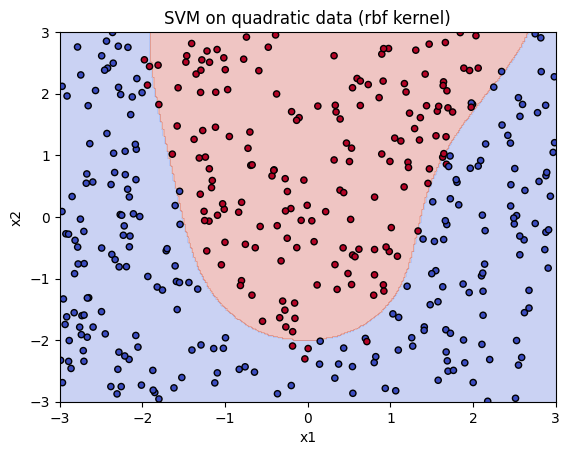

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

rng = np.random.default_rng(42)
X = rng.uniform(-3, 3, size=(400, 2))
# Class 1 if the point lies above the parabola x2 = x1^2 - 2 (with a little noise)
y = (X[:, 1] > X[:, 0]**2 - 2 + rng.normal(0, 0.3, 400)).astype(int)

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=5)
sc = StandardScaler()
x_train_s = sc.fit_transform(x_train)
x_test_s = sc.transform(x_test)

for kernel in ['linear', 'rbf']:
    svm = SVC(kernel=kernel, random_state=0).fit(x_train_s, y_train)
    pred = svm.predict(x_test_s)
    print(f'--- SVC kernel = {kernel} ---')
    print('Confusion Matrix:\n', confusion_matrix(y_test, pred))
    print('Accuracy:', accuracy_score(y_test, pred))
    print(classification_report(y_test, pred))

    # Decision boundary
    xx, yy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
    grid = sc.transform(np.c_[xx.ravel(), yy.ravel()])
    zz = svm.predict(grid).reshape(xx.shape)
    plt.contourf(xx, yy, zz, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=20)
    plt.title(f'SVM on quadratic data ({kernel} kernel)')
    plt.xlabel('x1'); plt.ylabel('x2')
    plt.show()